# IKpy Quickstart #

Import the IKPy module : 

In [3]:
import ikpy.chain
import numpy as np
import ikpy.utils.plot as plot_utils


The basic element of IKPy is the kinematic `Chain`.
To create a chain from an URDF file : 

In [4]:
# will give warnings, that's OK
my_chain = ikpy.chain.Chain.from_urdf_file("./ur5/ur5_gripper.urdf")

/local/standlm/lab-2-ik/.pixi/envs/default/lib/python3.12/site-packages/ikpy/chain.py:60: UserWarning: Link Base link (index: 0) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive
  warnings.warn("Link {} (index: {}) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive".format(link.name, link_index))
/local/standlm/lab-2-ik/.pixi/envs/default/lib/python3.12/site-packages/ikpy/chain.py:60: UserWarning: Link ee_fixed_joint (index: 7) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive
  warnings.warn("Link {} (index: {}) is of type 'fixed' but set as active in the active_links_mask. In practice, this fixed link doesn't provide any transformation so is as it were inactive".format(link.name, 

# Inverse kinematics

In Inverse Kinematics, you want the "end effector" of your robot to reach a specific 3D position (and in general, orientation) in space. The end effector is the final link of the robot arm, furthest from the base, and possibly a tool that is attached (a gripper in our robot model).

To have a more general representation of position, IKPy works with homogeneous coordinates. Homogenous coordinates are represented as a 4x4 matrix storing both position and orientation. Here we only consider (x,y,z) position, not orientation of the chain.

In [32]:
# define target X, Y, Z coordinate
target_position = [ 1.19, 0, 0]

In [33]:
# run inverse kinematics solver
print("The joint angles are : ", my_chain.inverse_kinematics(target_position))

The joint angles are :  [ 0.00000000e+00 -1.33161490e-01  7.54568699e-02 -1.28018370e-05
 -8.65374962e-01  1.36747275e+00  0.00000000e+00  0.00000000e+00]


You can check that the Inverse Kinematics is correct by comparing with the original position vector : 

In [34]:
# run forward kinematics on the inverse kinematics solution to verify
real_frame = my_chain.forward_kinematics(my_chain.inverse_kinematics(target_position))
print("Computed position vector : %s, goal position vector : %s" % (real_frame[:3, 3], target_position))

Computed position vector : [ 9.47278551e-01 -9.31214660e-08  1.81856657e-02], goal position vector : [1.19, 0, 0]


# Plotting
And finally plot the result : 

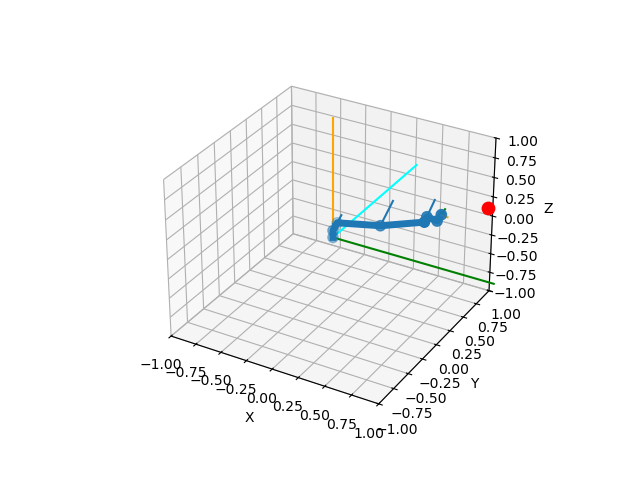

In [35]:
%matplotlib notebook
%matplotlib ipympl
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
fig, ax = plot_utils.init_3d_figure()

target_position = [ 1.19, .5, .5]

my_chain.plot(my_chain.inverse_kinematics(target_position), ax, target=target_position)


In [36]:
import random
import math
def randompoint(radius, center):
    x = random.gauss(0,1)
    y = random.gauss(0,1)
    z = random.gauss(0,1)

    point = np.array([x,y,z])
    norm = np.linalg.norm(point)
    

    return (point/norm * radius + center)

In [37]:
reachable_points = []

radius = .78
center = np.array([0.0, 0.0, 0.0])

for i in range(500):

    # Generate a random point and backgrack from inverse kinematics
    target_position = randompoint(radius, center)

    joint_angles = my_chain.inverse_kinematics(target_position)

    # Find actual end-effector position
    fk = my_chain.forward_kinematics(joint_angles)
    position = fk[:3, 3]

    # Check whether the robot reached the target
    if np.linalg.norm(position - target_position) < 0.01:
        reachable_points.append(position)

Estimated workspace volume: 1.9410255940644534 m³
Estimated workspace surface area: 7.554985572814119 m²


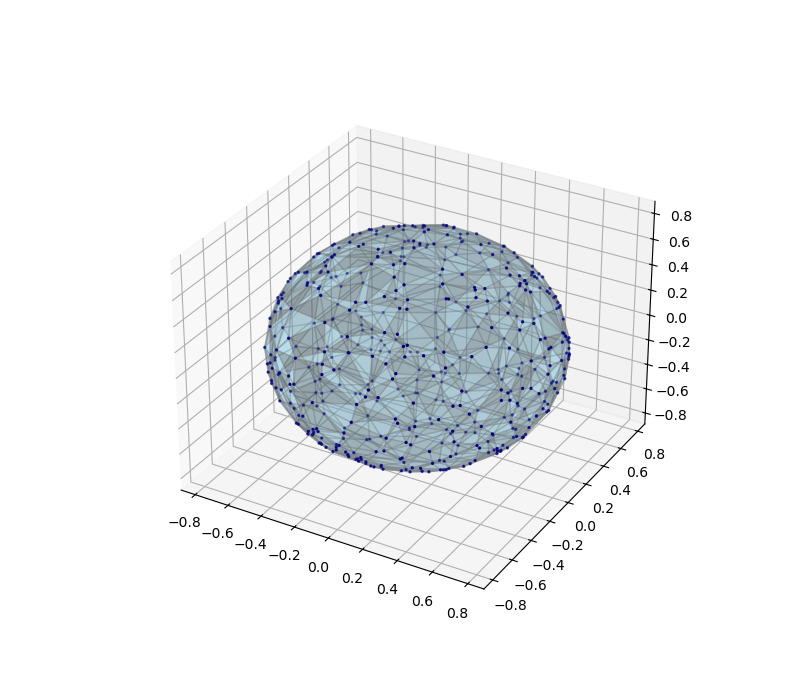

In [38]:
# Convert to NumPy array
points = np.asarray(reachable_points)

# Calculate convex hull
if len(points) < 4 or np.linalg.matrix_rank(
    points - points.mean(axis=0)
) < 3:
    raise ValueError("Need at least four non-coplanar reachable points.")

hull = ConvexHull(points)

print("Estimated workspace volume:", hull.volume, "m³")
print("Estimated workspace surface area:", hull.area, "m²")

# Plot workspace
fig = plt.figure(figsize=(8, 7))
ax = fig.add_subplot(111, projection="3d")

ax.plot_trisurf(
    points[:, 0],
    points[:, 1],
    points[:, 2],
    triangles=hull.simplices,
    color="skyblue",
    alpha=0.3,
    edgecolor="gray"
)

ax.scatter(
    points[:, 0],
    points[:, 1],
    points[:, 2],
    s=2,
    color="navy"
)


In [39]:
#COllision Checking, Defining and plotting a plane

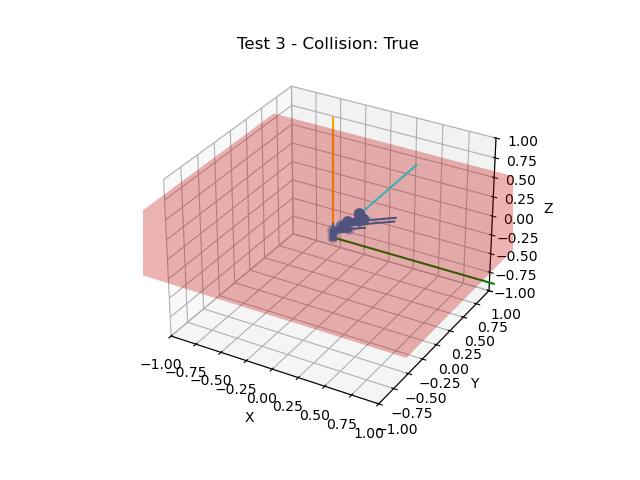

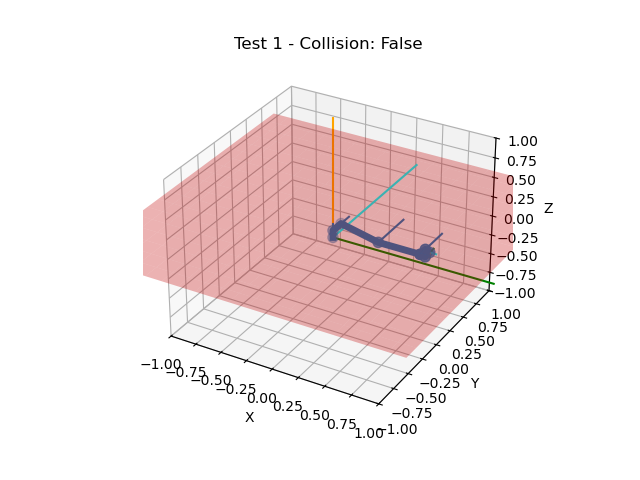

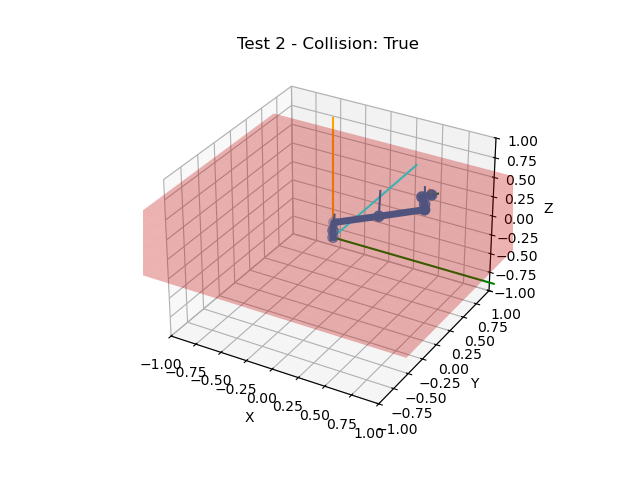

In [47]:
import numpy as np
import matplotlib.pyplot as plt
from ikpy.utils import geometry

# Get the joint positions
def get_nodes(chain, joints):
    nodes = []

    transformation_matrixes = chain.forward_kinematics(
        joints, full_kinematics=True
    )

    for index, link in enumerate(chain.links):
        node, orientation = geometry.from_transformation_matrix(
            transformation_matrixes[index]
        )
        nodes.append(node)

    return np.array(nodes)


# Define plane above the robot's zero pose
zero_joints = np.zeros(len(my_chain.links))
zero_nodes = get_nodes(my_chain, zero_joints)

plane_z = np.max(zero_nodes[:, 2]) + 0.1

# Check for collision with plane
def check_collision(chain, joints, plane_z):
    nodes = get_nodes(chain, joints)

    z_positions = nodes[:, 2]

    # All joints below plane
    if np.all(z_positions < plane_z):
        return False

    # All joints above plane
    if np.all(z_positions > plane_z):
        return False

    # Joints cross or touch plane
    return True

# we need 3 random test points
test1 = np.zeros(len(my_chain.links))

test2 = my_chain.inverse_kinematics([0.7, 0.5, 0.5])

test3 = my_chain.inverse_kinematics([0.6, -0.5, 0.8])

tests = [test1, test2, test3]
# Create the plane
x = np.linspace(-1.5, 1.5, 20)
y = np.linspace(-1.5, 1.5, 20)

X, Y = np.meshgrid(x, y)
Z = np.full_like(X, plane_z)

for i, joints in enumerate(tests):

    fig, ax = plot_utils.init_3d_figure()

    my_chain.plot(joints, ax)

    ax.plot_surface(
        X, Y, Z,
        color="red",
        alpha=0.3
    )

    collision = check_collision(my_chain, joints, plane_z)

    ax.set_title(
        f"Test {i + 1} - Collision: {collision}"
    )

plt.show()

TypeError: object of type 'numpy.float64' has no len()

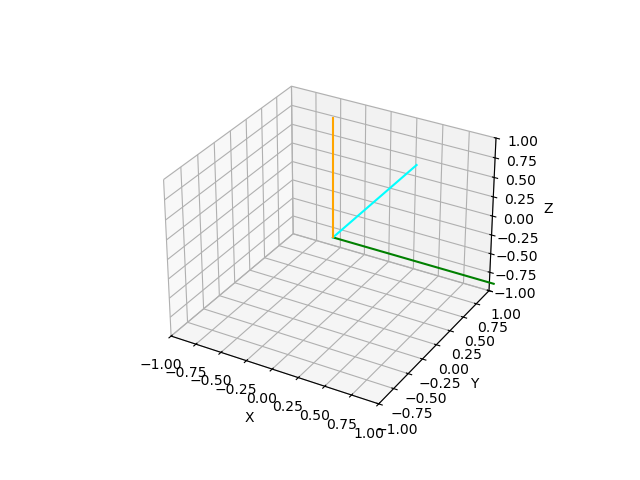